# LandMarks MediaPipe
## Aluno: João Maria de Araujo Nogueira Junior
Classificador de gestos de mão (pedra, papel e tesoura) treinado sobre os **landmarks** extraídos pelo MediaPipe, com fotos tiradas por mim da minha mão.

## Primeiros Passos
Instalei as bibliotecas, importei tudo e defini os hyperparametros.

In [ ]:
!pip install -q mediapipe opencv-python scikit-learn matplotlib pandas joblib

In [ ]:
import os, glob, random, urllib.request
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
import joblib

from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

seed = 42
random.seed(seed)
np.random.seed(seed)

### Hiperparâmetros
Defini o diretório das imagens, as 3 classes, o número de versões aumentadas a gerar por foto de treino, tamanho máximo do lado da imagem e proporção de teste.

In [ ]:
data_dir = "imgs_hands"
classes = ["rock", "paper", "scissor"]
n_aug = 15
max_side = 640
test_size = 0.2

## Load das imagens
Neste modulo se é carregado as fotos .jpg de cada pasta e eu tambem montei uma tabela com os caminhos, classe e rótulo numérico delas.

In [ ]:
records = []
for label, c in enumerate(classes):
    for p in sorted(glob.glob(os.path.join(data_dir, c, "*"))):
        if p.lower().endswith(".jpg"):
            records.append({"path": p, "class": c, "label": label})

df = pd.DataFrame(records)
assert len(df) > 0, f"Nenhum .jpg encontrado em '{data_dir}/'. Confira as pastas."
print(df["class"].value_counts())

def load_image(path, max_side=max_side):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    s = max_side / max(h, w)
    if s < 1:
        img = cv2.resize(img, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    return img

class
rock       20
paper      20
scissor    20
Name: count, dtype: int64


##Extração de landmarks com MediaPipe
Baixei o modelo hand_landmarker.task e criei o detector de mãos da API Tasks do MediaPipe. A função devolve os 21 pontos (x, y, z) de uma mão, ou "None" quando nenhuma mão é detectada.

In [ ]:
MODEL_PATH = "hand_landmarker.task"
MODEL_URL = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
if not os.path.exists(MODEL_PATH):
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path=MODEL_PATH),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.5,
)
detector = vision.HandLandmarker.create_from_options(options)

#21 pontos da mão
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (17, 18), (18, 19), (19, 20),
    (0, 17),
]

def extract_landmarks(img_rgb):
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(img_rgb))
    res = detector.detect(mp_img)
    if not res.hand_landmarks:
        return None, None
    pts = np.array([[p.x, p.y, p.z] for p in res.hand_landmarks[0]], dtype=np.float32)
    return pts, pts

def draw_landmarks(img_rgb, hand):
    out = img_rgb.copy()
    h, w = out.shape[:2]
    xy = (hand[:, :2] * [w, h]).astype(int)
    for a, b in HAND_CONNECTIONS:
        cv2.line(out, tuple(xy[a]), tuple(xy[b]), (0, 255, 255), 2)
    for x, y in xy:
        cv2.circle(out, (int(x), int(y)), 4, (255, 0, 0), -1)
    return out


##Visualização dos Landmarks gerados pelo MediaPipe
Plotei 4 fotos de cada classe com os landmarks detectados desenhados por cima.
Infelizmente o mediapipe não detectou algumas das minhas mão então acabei perdendo uma parte do já pequeno dataset, com sorte o data augmentation que vou realizar nos dados ajudar nesse quesito.

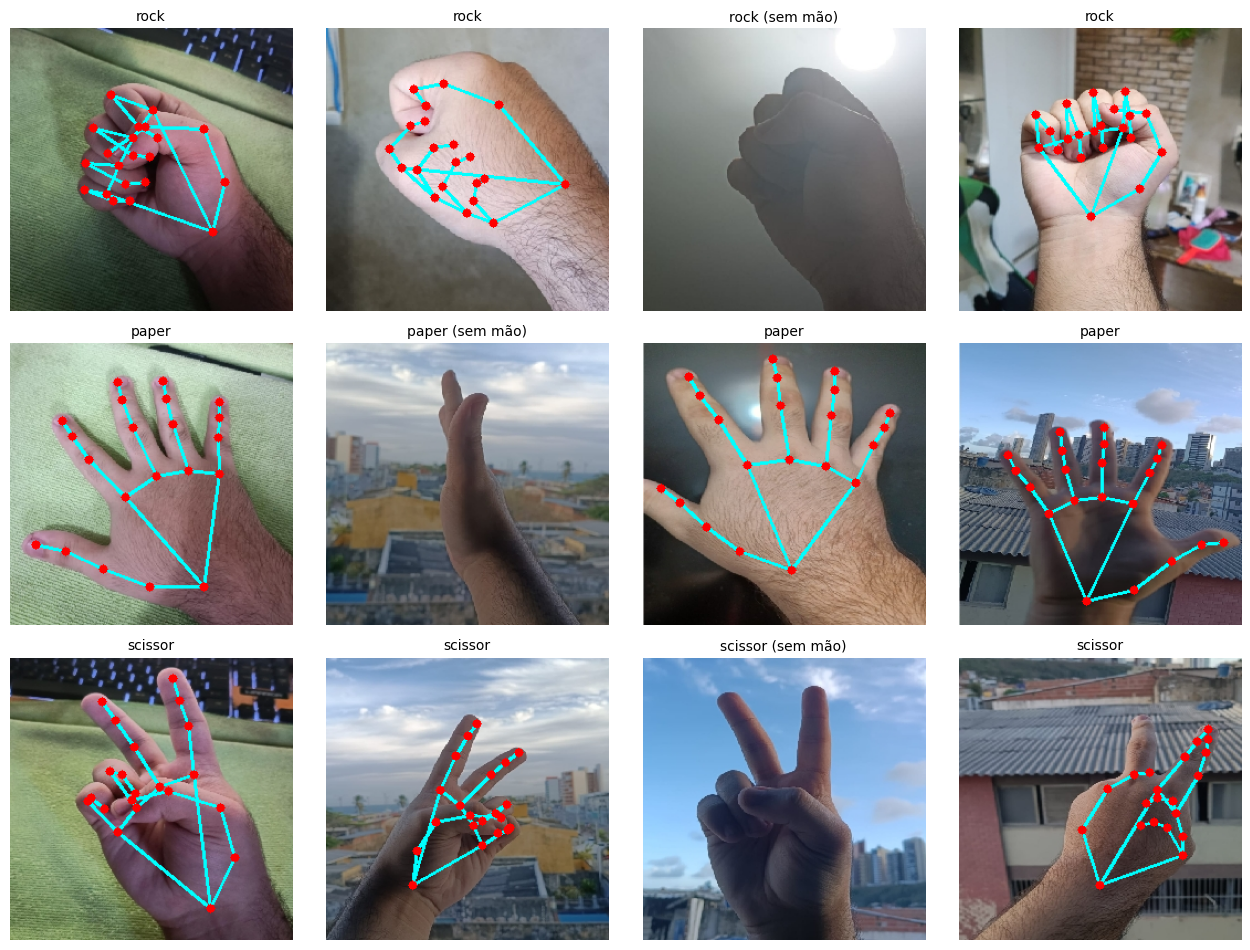

In [ ]:
n_show = 4
fig, axes = plt.subplots(len(classes), n_show, figsize=(3.2 * n_show, 3.2 * len(classes)))
for i, c in enumerate(classes):
    paths = df[df["class"] == c]["path"].head(n_show).tolist()
    for j, p in enumerate(paths):
        img = load_image(p)
        pts, hand = extract_landmarks(img)
        axes[i, j].imshow(img if hand is None else draw_landmarks(img, hand))
        axes[i, j].set_title(f"{c}" + ("" if hand is not None else " (sem mão)"), fontsize=10)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

##Divisão treino e teste
Separei treino e teste de forma estratificada **antes** de qualquer augmentation. Assim nenhuma versão aumentada de uma foto de teste vaza para o treino.

In [ ]:
df_train, df_test = train_test_split(
    df, test_size=test_size, stratify=df["label"], random_state=seed
)
print("Treino (fotos originais):", len(df_train), "| Teste:", len(df_test))
print(df_train["class"].value_counts().to_dict(), df_test["class"].value_counts().to_dict())

Treino (fotos originais): 48 | Teste: 12
{'scissor': 16, 'rock': 16, 'paper': 16} {'rock': 4, 'scissor': 4, 'paper': 4}


##Data augmentation nas imagens
Defini transformações aplicadas nas imagens, foquei nas de rotação, zoom, deslocamento, espelhamento e variação de brilho e contraste. Apos isso o MediaPipe roda sobre cada versão aumentada.

In [ ]:
import albumentations as A

def augment(img, rng):
    #pipeline de transforms
    transform = A.Compose([
        A.ShiftScaleRotate(
            shift_limit=0.1,
            scale_limit=0.2,
            rotate_limit=25,
            border_mode=cv2.BORDER_REPLICATE,
            p=1.0
        ),
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=1.0),
        A.GaussianBlur(blur_limit=(3, 5), p=0.3)
    ])

    #transformação sobre a imagem
    augmented = transform(image=img)
    return augmented["image"]

Abaixo plotei para cada classe algumas das transformações e seus respectivos landmarks detectados em cada uma, novamente para ter uma ideia visual de como as imagens vão estar.

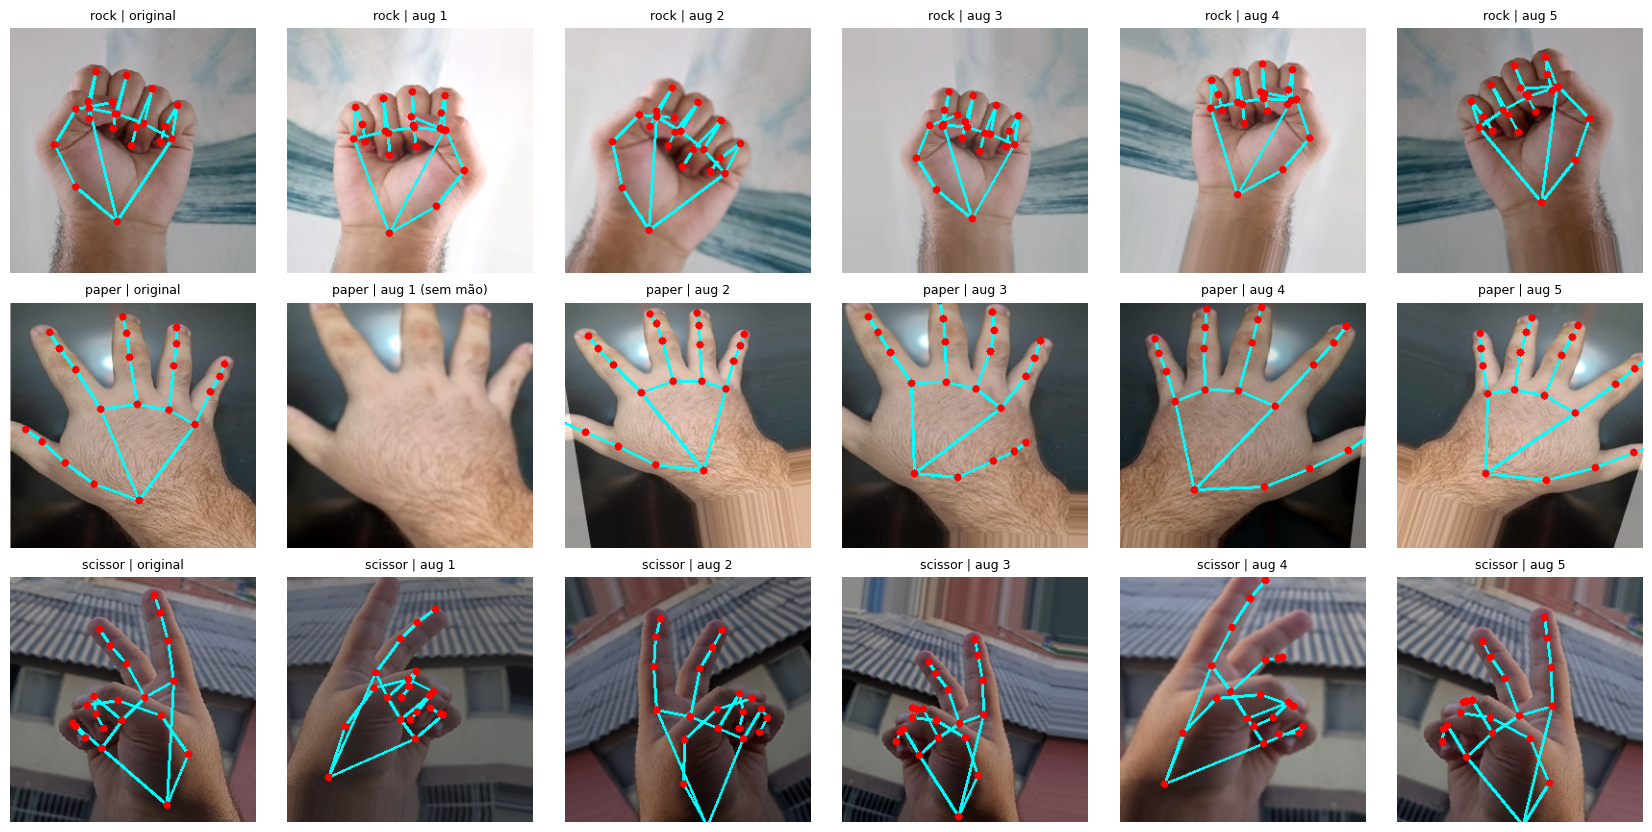

In [ ]:
rng_demo = np.random.default_rng(seed)
n_cols = 6
fig, axes = plt.subplots(len(classes), n_cols, figsize=(2.8 * n_cols, 2.8 * len(classes)))
for i, c in enumerate(classes):
    p = df_train[df_train["class"] == c]["path"].iloc[0]
    base = load_image(p)
    variants = [base] + [augment(base, rng_demo) for _ in range(n_cols - 1)]
    for j, im in enumerate(variants):
        pts, hand = extract_landmarks(im)
        axes[i, j].imshow(im if hand is None else draw_landmarks(im, hand))
        tag = "original" if j == 0 else f"aug {j}"
        axes[i, j].set_title(f"{c} | {tag}" + ("" if hand is not None else " (sem mão)"), fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

## Normalização
Subtraí o pulso dos demais pontos para a posição da mão não importar, e dividi pela distância pulso até base do dedo médio, para o tamanho não importar.

O resultado das funções abaixo é um vetor "flattened" com as cordenadas normalizadas ou cruas.

In [ ]:
def normalize(pts):#retorna os pontos normalizados :D
    p = pts - pts[0]# translação
    scale = np.linalg.norm(p[9, :2])# escala
    if scale < 1e-6:
        scale = 1.0
    return (p / scale).flatten()

def raw_features(pts):# sem normalizar
    return pts.flatten()

Plotei a mesma mão com as coordenadas brutas e normalizadas pra ter uma noção visual de como ambos os resultados se comportam e diferem.

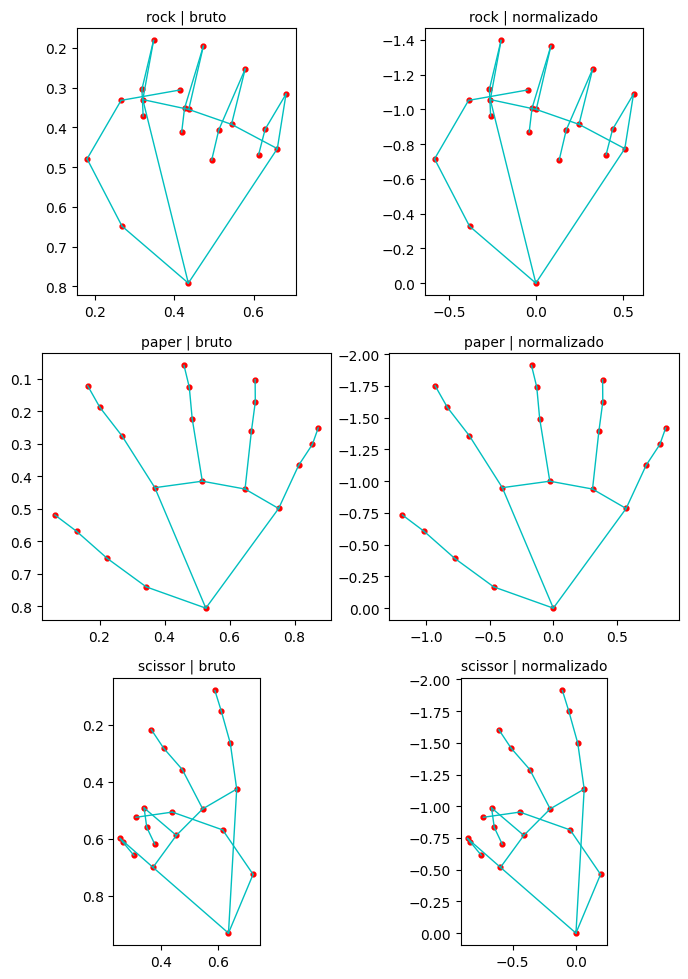

In [ ]:
fig, axes = plt.subplots(len(classes), 2, figsize=(7, 3.3 * len(classes)))
for i, c in enumerate(classes):
    p = df_train[df_train["class"] == c]["path"].iloc[0]
    pts, hand = extract_landmarks(load_image(p))
    if pts is None:
        continue
    norm = normalize(pts).reshape(21, 3)
    for ax, data, title in [(axes[i, 0], pts, f"{c} | bruto"), (axes[i, 1], norm, f"{c} | normalizado")]:
        for a, b in HAND_CONNECTIONS:
            ax.plot([data[a, 0], data[b, 0]], [data[a, 1], data[b, 1]], "c-", lw=1)
        ax.scatter(data[:, 0], data[:, 1], c="r", s=12)
        ax.invert_yaxis()
        ax.set_aspect("equal")
        ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

## Construção do dataset de landmarks
Extraí os landmarks das fotos originais e das versões aumentadas pro treino. tambem aproveitei pra contar quantas imagens ficaram sem mão detectada por classe já que os plots anteriores me fizeram suspeitar que fosse um grande numero.

In [ ]:
def build_dataset(df_part, n_aug=0, seed_val=seed):
    rng = np.random.default_rng(seed_val)
    pts_all, y, groups, paths = [], [], [], []
    lost = {c: 0 for c in classes}
    for gid, row in df_part.iterrows():
        img = load_image(row["path"])
        variants = [img] + [augment(img, rng) for _ in range(n_aug)]
        for im in variants:
            pts, _ = extract_landmarks(im)
            if pts is None:
                lost[row["class"]] += 1
                continue
            pts_all.append(pts)
            y.append(row["label"])
            groups.append(gid)# id da foto original
            paths.append(row["path"])
    return np.array(pts_all), np.array(y), np.array(groups), paths, lost

P_train, y_train, g_train, _, lost_train = build_dataset(df_train, n_aug=n_aug)
P_test,  y_test,  g_test,  paths_test, lost_test = build_dataset(df_test, n_aug=0)

X_train      = np.array([normalize(p) for p in P_train])
X_test       = np.array([normalize(p) for p in P_test])
X_train_raw  = np.array([raw_features(p) for p in P_train])
X_test_raw   = np.array([raw_features(p) for p in P_test])

print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Sem mão detectada (treino):", lost_train)
print("Sem mão detectada (teste): ", lost_test)
print("Amostras por classe (treino):", dict(zip(classes, np.bincount(y_train, minlength=len(classes)))))

Treino: (509, 63) | Teste: (5, 63)
Sem mão detectada (treino): {'rock': 145, 'paper': 10, 'scissor': 104}
Sem mão detectada (teste):  {'rock': 3, 'paper': 2, 'scissor': 2}
Amostras por classe (treino): {'rock': np.int64(111), 'paper': np.int64(246), 'scissor': np.int64(152)}


Como observado, pelo resultado, é supreedentemente bem comum que o MediaPipe não consiga entender o formato peculiar de minha pequena mão, mesmo sobre uma iluminação ambiente razovel.

## Arquitetura do Modelo
Optei por utilizar uma rede neural MLP como o classificador de gestos.

In [ ]:
def make_final_model():
    return make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1500, random_state=seed))

## Treinamento e Avaliação
Treinei o classificador com os dados normalizados obtidos no processo de extração e avaliei o resultado geral no conjunto de teste.

In [ ]:
final_model_pipeline = make_final_model()
final_model_pipeline.fit(X_train, y_train)

# Avaliação
y_pred = final_model_pipeline.predict(X_test)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
rec = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

results = pd.DataFrame([{
    "acurácia": round(acc, 3),
    "precisão": round(prec, 3),
    "recall": round(rec, 3),
    "F1": round(f1, 3)
}])
display(results)

,acurácia,precisão,recall,F1
0,1.0,1.0,1.0,1.0


### Desempenho Detalhado
Abaixo estão detalhadas as métricas de precisão, recall e F1-score para cada um dos gestos possíveis no conjunto de teste.

In [ ]:
y_pred = final_model_pipeline.predict(X_test)
report = classification_report(y_test, y_pred, target_names=classes, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T.round(3)
report_df.loc["accuracy", ["precision", "recall"]] = np.nan
report_df.loc["accuracy", "f1-score"] = round(accuracy_score(y_test, y_pred), 3)
report_df.loc["accuracy", "support"] = len(y_test)
print(f"Total de fotos avaliadas no teste: {len(y_test)}")
display(report_df)

Total de fotos avaliadas no teste: 5


,precision,recall,f1-score,support
rock,1.0,1.0,1.0,1.0
paper,1.0,1.0,1.0,2.0
scissor,1.0,1.0,1.0,2.0
accuracy,NaN,NaN,1.0,5.0
macro avg,1.0,1.0,1.0,5.0
weighted avg,1.0,1.0,1.0,5.0


## Teste com dados não normalizados
Pra ver se existia alguma diferença entre a eficiencia do modelo treinado em cima dados normalizados ou brutos eu resolvi re-treinar a mlp em cima dos dados brutos.

In [ ]:
raw_model = make_final_model()
raw_model.fit(X_train_raw, y_train)

acc_norm = accuracy_score(y_test, final_model_pipeline.predict(X_test))
acc_raw  = accuracy_score(y_test, raw_model.predict(X_test_raw))
display(pd.DataFrame({"features": ["bruto", "normalizado"], "acurácia no teste": [round(acc_raw, 3), round(acc_norm, 3)]}))

,features,acurácia no teste
0,bruto,1.0
1,normalizado,1.0


Ambos obtiveram uma acuracia perfeita, talvez porque o numero factual de dados e de rotulos desse modelo sejam limitados.

## Comparação Real e Predição
Para 2 fotos de teste de cada classe, mostrei a imagem com os landmarks detectados duas vezes à da esquerda é a com a classe real e à da direita é a com a classe prevista.

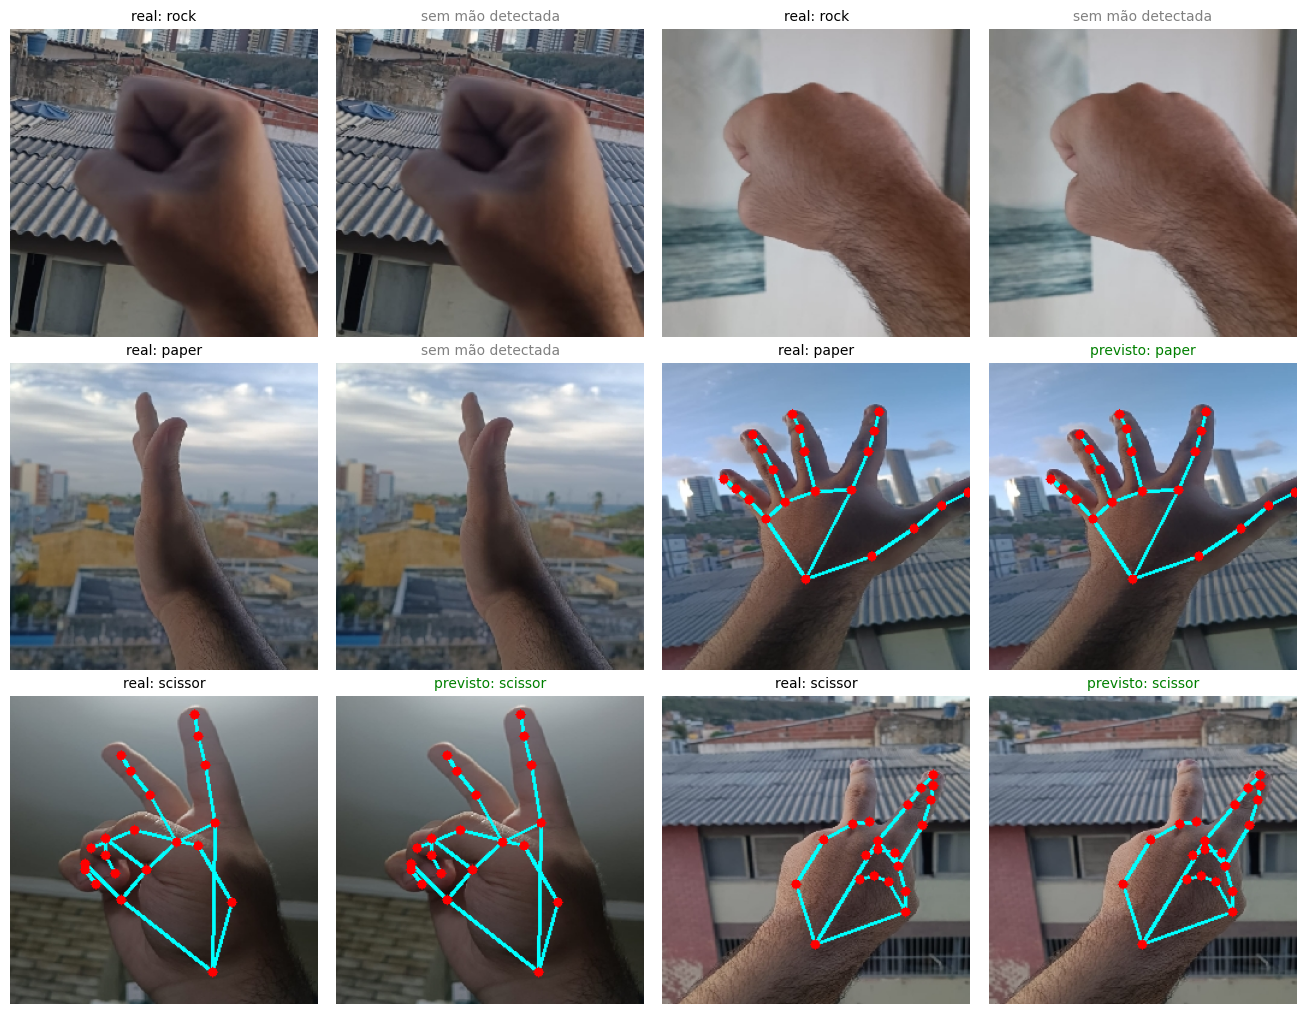

In [ ]:
n_per_class = 2
sel = pd.concat([df_test[df_test["class"] == c].head(n_per_class) for c in classes])

fig, axes = plt.subplots(len(classes), 2 * n_per_class, figsize=(3.3 * 2 * n_per_class, 3.4 * len(classes)))
k = 0
for i, c in enumerate(classes):
    for j in range(n_per_class):
        ax_real, ax_pred = axes[i, 2 * j], axes[i, 2 * j + 1]
        row = sel[sel["class"] == c].iloc[j]
        img = load_image(row["path"])
        pts, hand = extract_landmarks(img)
        if hand is None:
            ax_real.imshow(img); ax_pred.imshow(img)
            ax_real.set_title(f"real: {c}", fontsize=10); ax_pred.set_title("sem mão detectada", fontsize=10, color="gray")
        else:
            pred = classes[int(final_model_pipeline.predict(normalize(pts).reshape(1, -1))[0])]
            shown = draw_landmarks(img, hand)
            ax_real.imshow(shown); ax_pred.imshow(shown)
            ax_real.set_title(f"real: {c}", fontsize=10)
            ax_pred.set_title(f"previsto: {pred}", fontsize=10, color="green" if pred == c else "red")
        ax_real.axis("off"); ax_pred.axis("off")
plt.tight_layout()
plt.show()

## Conclusão
Embora o experimento possa ter sido afetado pelo baixo repositorio de dados, acredito que o principal contribuinte para o excedente de falsos negativos seja principalmente a escolha de posicionamento, angulo e iluminação de algumas das mão. Acabei por superestimar a capacidade do MediaPipe de inferenciar landmarks mesmo com dedos obstruidos é provavel que um fine-tunning do proprio MediaPipe pudesse concertar os problemas que eu encontrei aqui, entretanto isso exigiria uma quantidade de dados muito superior aos que pude coletar de minhas mãos em uma tarde com 25% bateria.

Entranto, gostaria de concluir que o classificador fez um otimo trabalho dado as entradas que recebeu ele acabou conseguindo uma acuracia impressionante.